# 01.2. Конструирование признаков

Вход: data/processed/ и models/fill_pipeline.joblib из ноутбука 01. Тестовая выборка не используется.


In [1]:
import modules, pkgutil
print(modules.__file__)
print(sorted(m.name for m in pkgutil.iter_modules(modules.__path__)))

C:\Users\6anna\PycharmProjects\Suhodolova_Anna_Lab2\modules\__init__.py
['config', 'features', 'modeling', 'preprocessing']


In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate

sys.path.insert(0, str(Path("..").resolve()))   # чтобы работал import modules
from modules.config import  RANDOM_STATE
from modules.features import FEATURE_GROUPS, FeatureBuilder
from modules.modeling import build_pipeline, load_processed

# Пути
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Один раз делим на части(фолды), для всех проверок
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["axes.axisbelow"] = True

X_fit, y_fit, X_val, y_val, clean_val, valid_flags = load_processed(PROCESSED_DIR)
print(f"обучение: {len(X_fit)} строк, признаков: {X_fit.shape[1]}")

NameError: name 'RANDOM_STATE' is not defined

## 1. Группы новых признаков и гипотезы

| Группа | Признаки | Гипотеза |
|---|---|---|
| **`logs`** | `log_total_area`, `log_distance_to_center`, `log_metro_distance` | Площадь и расстояния влияют на цену нелинейно: первые метры до метро важнее, чем последующие |
| **`age`** | `house_age`, `is_new_house`, `is_old_house` | Новостройки дороже, старые дома дешевле |
| **`floors`** | `floor_ratio`, `is_first_floor`, `is_last_floor` | Первый и последний этажи дешевле; доля этажа учитывает высоту дома |
| **`shares`** | `area_per_room`, `kitchen_share`, `living_share`, `tenants_per_room` | Просторность и качество планировки: большая кухня и жилая площадь на комнату = дороже |
| **`tenants`** | `area_per_tenant`, `living_area_per_room` | Чем больше площади на человека — тем комфортнее и дороже |
| **`center`** | `center_close`, `metro_close` | Близость к центру и метро даёт премию к цене (пороговый эффект) |
| **`listing`** | `photo_density`, `missing_count` | Больше фото и меньше пропусков = внимательный арендодатель = выше цена |
| **`interactions`** | `area_x_distance`, `area_x_age`, `area_x_metro` | Цена за м² зависит от локации и возраста: большая квартира в центре ценится сильнее |
| **`crosses`** | `district_house_type`, `district_renovation`, `house_type_renovation` | Сочетания важны: евроремонт в центре даёт больше, чем на окраине; в монолите ремонт ценится иначе |

In [3]:
def cv_mae(groups):
    """CV MAE Ridge на log1p(цены) для выбранных групп признаков (пустой список — без новых признаков)."""
    pipe = build_pipeline(Ridge(alpha=10), groups=groups)
    cv = cross_validate(pipe, X_fit, y_fit, cv=CV, scoring="neg_mean_absolute_error", n_jobs=-1)
    return -cv["test_score"].mean(), cv["test_score"].std()

# модель без новых признаков
base_mae, base_std = cv_mae([])
# Каждая группа отдельно
alone = {g: cv_mae([g]) for g in FEATURE_GROUPS}
alone_table = pd.DataFrame({
    "CV_MAE": {g: v[0] for g, v in alone.items()},
    "CV_MAE_std": {g: v[1] for g, v in alone.items()},
})
alone_table["Δ к базе, ₽"] = alone_table["CV_MAE"] - base_mae
alone_table["Δ к базе, %"] = alone_table["Δ к базе, ₽"] / base_mae * 100
print(f"База (без новых признаков): CV MAE {base_mae:,.0f} ± {base_std:,.0f} ₽")
alone_table.sort_values("CV_MAE").round(2)

База (без новых признаков): CV MAE 3,948 ± 93 ₽


,CV_MAE,CV_MAE_std,"Δ к базе, ₽","Δ к базе, %"
logs,3676.10,41.55,-272.21,-6.89
crosses,3775.65,85.13,-172.66,-4.37
shares,3829.99,30.91,-118.32,-3.00
listing,3870.87,54.38,-77.43,-1.96
interactions,3873.51,58.15,-74.80,-1.89
center,3923.45,91.03,-24.86,-0.63
tenants,3930.55,82.99,-17.76,-0.45
floors,3930.97,86.24,-17.34,-0.44
age,3936.69,100.47,-11.62,-0.29


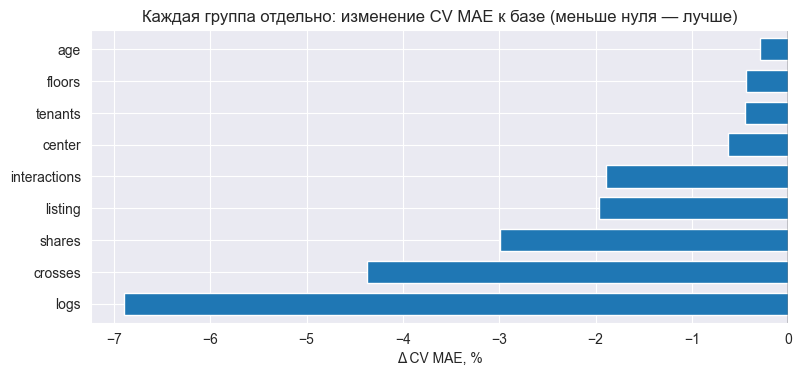

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
alone_table["Δ к базе, %"].sort_values().plot(kind="barh", ax=ax, width=0.7)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Каждая группа отдельно: изменение CV MAE к базе (меньше нуля — лучше)")
ax.set_xlabel("Δ CV MAE, %")
plt.show()

## 2. Жадный отбор групп

На каждом шаге пробуем добавить каждую из оставшихся групп и берём ту, что сильнее всего снижает CV MAE. Останавливаемся, когда лучший шаг даёт улучшение меньше порога.

In [6]:
MIN_GAIN = 0.005   # группа нужна, если снижает CV MAE хотя бы на 0.2 %

selected, current = [], base_mae
history = [{"шаг": 0, "добавлена группа": "—", "CV_MAE": base_mae, "выигрыш, %": 0.0}]
remaining = list(FEATURE_GROUPS)
while remaining:
    # Ошибка набора, если добавить каждую из оставшихся групп
    scores = {g: cv_mae(selected + [g])[0] for g in remaining}
    best_group = min(scores, key=scores.get)
    # Лучший шаг не дотягивает до порога: останавливаемся
    if scores[best_group] > current * (1 - MIN_GAIN):
        break
    history.append({"шаг": len(selected) + 1, "добавлена группа": best_group, "CV_MAE": scores[best_group],
                    "выигрыш, %": (1 - scores[best_group] / current) * 100})
    selected.append(best_group)
    remaining.remove(best_group)
    current = scores[best_group]

print("Выбранные группы:", selected or "ни одна не улучшает модель")
print("Не вошли:", remaining)
pd.DataFrame(history).set_index("шаг").round(2)
# Итого выбранные группы
final_mae, final_std = cv_mae(selected)
print(f"Вывод: выбраны группы {selected or 'нет'}, CV MAE {base_mae:,.0f} -> {final_mae:,.0f} ₽ "
      f"({(1 - final_mae / base_mae) * 100:.1f} %); не прошли порог: {remaining or 'нет'}")

Выбранные группы: ['logs', 'crosses', 'floors']
Не вошли: ['age', 'shares', 'tenants', 'center', 'listing', 'interactions']


,добавлена группа,CV_MAE,"выигрыш, %"
шаг,,,
0,—,3948.31,0.00
1,logs,3676.10,6.89
2,crosses,3477.44,5.40
3,floors,3459.08,0.53


Вывод: выбраны группы ['logs', 'crosses', 'floors'], CV MAE 3,948 -> 3,459 ₽ (12.4 %); не прошли порог: ['age', 'shares', 'tenants', 'center', 'listing', 'interactions']
